## Problem 13: Predicting GDP Growth Under Climate Stress Using Economic, Energy and Temperature Indicators

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [5]:
co2_url = (
    "https://raw.githubusercontent.com/"
    "owid/co2-data/master/owid-co2-data.csv"
)

columns_needed = [
    "country",
    "year",
    "iso_code",
    "population",
    "gdp",
    "co2_growth_prct",
    "co2_per_capita",
    "co2_per_gdp",
    "energy_per_capita",
    "energy_per_gdp",
    "coal_co2_per_capita",
    "oil_co2_per_capita"
]

co2_df = pd.read_csv(
    co2_url,
    usecols=columns_needed
)

co2_df.head()

,country,year,iso_code,population,gdp,co2_growth_prct,co2_per_capita,co2_per_gdp,coal_co2_per_capita,energy_per_capita,energy_per_gdp,oil_co2_per_capita
0,Afghanistan,1750,AFG,2802560.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
co2_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50411 entries, 0 to 50410
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   country              50411 non-null  str    
 1   year                 50411 non-null  int64  
 2   iso_code             42480 non-null  str    
 3   population           41167 non-null  float64
 4   gdp                  15251 non-null  float64
 5   co2_growth_prct      26239 non-null  float64
 6   co2_per_capita       26509 non-null  float64
 7   co2_per_gdp          17528 non-null  float64
 8   coal_co2_per_capita  21314 non-null  float64
 9   energy_per_capita    10586 non-null  float64
 10  energy_per_gdp       7787 non-null   float64
 11  oil_co2_per_capita   24722 non-null  float64
dtypes: float64(9), int64(1), str(2)
memory usage: 4.6 MB


In [8]:
co2_df.isna().sum()

country                    0
year                       0
iso_code                7931
population              9244
gdp                    35160
co2_growth_prct        24172
co2_per_capita         23902
co2_per_gdp            32883
coal_co2_per_capita    29097
energy_per_capita      39825
energy_per_gdp         42624
oil_co2_per_capita     25689
dtype: int64

In [9]:
co2_df = co2_df[
    co2_df["iso_code"].notna()
].copy()

co2_df = co2_df[
    ~co2_df["iso_code"].str.startswith(
        "OWID_"
    )
].copy()

In [10]:
co2_df[[
    "country",
    "iso_code"
]].drop_duplicates().head(20)

,country,iso_code
0,Afghanistan,AFG
725,Albania,ALB
900,Algeria,DZA
1075,Andorra,AND
1350,Angola,AGO
1525,Anguilla,AIA
1700,Antarctica,ATA
1975,Antigua and Barbuda,ATG
2150,Argentina,ARG
2325,Armenia,ARM


In [11]:
temperature_url = (
    "https://ourworldindata.org/grapher/"
    "average-annual-surface-temperature.csv"
    "?v=1&csvType=full&useColumnShortNames=false"
)

temperature_df = pd.read_csv(
    temperature_url,
    storage_options={
        "User-Agent": "Mozilla/5.0"
    }
)

temperature_df.head()

,Entity,Code,Year,Average surface temperature
0,Afghanistan,AFG,1940,11.327695
1,Afghanistan,AFG,1941,13.324756
2,Afghanistan,AFG,1942,12.885448
3,Afghanistan,AFG,1943,11.524769
4,Afghanistan,AFG,1944,12.143665


In [12]:
temperature_column = [
    column
    for column in temperature_df.columns
    if column not in [
        "Entity",
        "Code",
        "Year"
    ]
][0]

temperature_df = temperature_df.rename(
    columns={
        "Entity": "country",
        "Code": "iso_code",
        "Year": "year",
        temperature_column: "temperature"
    }
)

temperature_df = temperature_df[[
    "country",
    "iso_code",
    "year",
    "temperature"
]].copy()

temperature_df.head()

,country,iso_code,year,temperature
0,Afghanistan,AFG,1940,11.327695
1,Afghanistan,AFG,1941,13.324756
2,Afghanistan,AFG,1942,12.885448
3,Afghanistan,AFG,1943,11.524769
4,Afghanistan,AFG,1944,12.143665


**Merge Climate and Economic Data**

In [13]:
df = pd.merge(
    co2_df,
    temperature_df[[
        "iso_code",
        "year",
        "temperature"
    ]],
    on=[
        "iso_code",
        "year"
    ],
    how="inner"
)

df.head()

,country,year,iso_code,population,gdp,co2_growth_prct,co2_per_capita,co2_per_gdp,coal_co2_per_capita,energy_per_capita,energy_per_gdp,oil_co2_per_capita,temperature
0,Afghanistan,1940,AFG,6468510.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.327695
1,Afghanistan,1941,AFG,6528377.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.324756
2,Afghanistan,1942,AFG,6608815.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.885448
3,Afghanistan,1943,AFG,6710138.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.524769
4,Afghanistan,1944,AFG,6813016.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.143665


In [14]:
df.shape

(15725, 13)

In [15]:
df = df[
    df["year"] >= 1990
].copy()

df = df.sort_values(
    by=[
        "country",
        "year"
    ]
)

df.head()

,country,year,iso_code,population,gdp,co2_growth_prct,co2_per_capita,co2_per_gdp,coal_co2_per_capita,energy_per_capita,energy_per_gdp,oil_co2_per_capita,temperature
50,Afghanistan,1990,AFG,12045664.0,1.306598e+10,-26.784,0.168,0.155,0.023,2506.867,2.311,0.106,12.222920
51,Afghanistan,1991,AFG,12238879.0,1.204736e+10,-5.435,0.156,0.159,0.020,1021.075,1.037,0.098,11.212434
52,Afghanistan,1992,AFG,13278983.0,1.267754e+10,-22.580,0.112,0.117,0.002,618.055,0.647,0.078,10.987166
53,Afghanistan,1993,AFG,14943175.0,9.834582e+09,0.330,0.100,0.151,0.001,545.758,0.829,0.070,11.510678
54,Afghanistan,1994,AFG,16250800.0,7.919856e+09,-2.227,0.089,0.184,0.001,484.346,0.994,0.064,11.846118


**Construct GDP Per Capita**

In [16]:
df["gdp_per_capita"] = (
    df["gdp"]
    / df["population"]
)

df.loc[
    df["gdp_per_capita"] <= 0,
    "gdp_per_capita"
] = np.nan

**Current GDP-Per-Capita Growth**

In [17]:
df["current_gdp_pc_growth"] = (
    df.groupby("country")[
        "gdp_per_capita"
    ]
    .pct_change(
        fill_method=None
    )
    * 100
)

In [18]:
df["future_gdp_pc_growth"] = (
    df.groupby("country")[
        "current_gdp_pc_growth"
    ]
    .shift(-1)
)

In [19]:
df["log_gdp_pc"] = np.log(
    df["gdp_per_capita"]
)

In [20]:
df["population_growth"] = (
    df.groupby("country")[
        "population"
    ]
    .pct_change(
        fill_method=None
    )
    * 100
)

In [21]:
df["temperature_change"] = (
    df.groupby("country")[
        "temperature"
    ]
    .diff()
)

In [22]:
df["temperature_squared"] = (
    df["temperature"] ** 2
)

In [23]:
df["heat_stress"] = (
    df["temperature"] - 13
).clip(lower=0)

In [24]:
df = df.rename(
    columns={
        "co2_growth_prct":
        "co2_growth"
    }
)

In [25]:
climate_features = [
    "temperature",
    "temperature_squared",
    "temperature_change",
    "heat_stress"
]

In [26]:
economic_features = [
    "current_gdp_pc_growth",
    "log_gdp_pc",
    "population_growth",
    "co2_growth",
    "co2_per_capita",
    "co2_per_gdp",
    "energy_per_capita",
    "energy_per_gdp",
    "coal_co2_per_capita",
    "oil_co2_per_capita"
]

In [27]:
features = (
    climate_features
    + economic_features
)

print(
    "Number of predictors:",
    len(features)
)

Number of predictors: 14


In [28]:
model_df = df[[
    "country",
    "iso_code",
    "year"
] + features + [
    "future_gdp_pc_growth"
]].copy()

model_df = model_df.replace(
    [np.inf, -np.inf],
    np.nan
)

model_df = model_df.dropna()

model_df.head()

,country,iso_code,year,temperature,temperature_squared,temperature_change,heat_stress,current_gdp_pc_growth,log_gdp_pc,population_growth,co2_growth,co2_per_capita,co2_per_gdp,energy_per_capita,energy_per_gdp,coal_co2_per_capita,oil_co2_per_capita,future_gdp_pc_growth
51,Afghanistan,AFG,1991,11.212434,125.718676,-1.010486,0.0,-9.251608,6.891983,1.604021,-5.435,0.156,0.159,1021.075,1.037,0.020,0.098,-3.011588
52,Afghanistan,AFG,1992,10.987166,120.717817,-0.225268,0.0,-3.011588,6.861405,8.498360,-22.580,0.112,0.117,618.055,0.647,0.002,0.078,-31.064509
53,Afghanistan,AFG,1993,11.510678,132.495708,0.523512,0.0,-31.064509,6.489406,12.532526,0.330,0.100,0.151,545.758,0.829,0.001,0.070,-25.949239
54,Afghanistan,AFG,1994,11.846118,140.330512,0.335440,0.0,-25.949239,6.188986,8.750650,-2.227,0.089,0.184,484.346,0.994,0.001,0.064,47.979170
55,Afghanistan,AFG,1995,11.725228,137.480972,-0.120890,0.0,47.979170,6.580888,5.015365,-2.511,0.083,0.115,386.490,0.536,0.001,0.059,-5.779412


In [29]:
country_counts = (
    model_df
    .groupby("country")
    .size()
)

valid_countries = (
    country_counts[
        country_counts >= 15
    ]
    .index
)

model_df = model_df[
    model_df["country"].isin(
        valid_countries
    )
].copy()

In [30]:
print(
    "Countries:",
    model_df["country"].nunique()
)

print(
    "Observations:",
    len(model_df)
)

print(
    "Years:",
    model_df["year"].min(),
    "to",
    model_df["year"].max()
)

Countries: 122
Observations: 3628
Years: 1991 to 2021


In [31]:
model_df[
    features
    + ["future_gdp_pc_growth"]
].describe().round(3)

,temperature,temperature_squared,temperature_change,heat_stress,current_gdp_pc_growth,log_gdp_pc,population_growth,co2_growth,co2_per_capita,co2_per_gdp,energy_per_capita,energy_per_gdp,coal_co2_per_capita,oil_co2_per_capita,future_gdp_pc_growth
count,3628.000,3628.000,3628.000,3628.000,3628.000,3628.000,3628.000,3628.000,3628.000,3628.000,3628.000,3628.000,3628.000,3628.000,3628.000
mean,16.061,323.667,0.021,5.230,2.453,9.207,1.195,2.249,5.718,0.358,28688.637,1.632,1.407,2.404,2.551
std,8.107,247.977,0.627,5.439,6.456,1.145,1.610,11.178,6.972,0.333,34898.698,1.330,2.169,2.842,5.555
min,-4.912,0.000,-2.810,0.000,-63.040,6.044,-7.796,-93.979,0.021,0.031,117.998,0.166,0.000,0.013,-31.904
25%,9.679,93.685,-0.321,0.000,0.524,8.468,0.292,-2.707,1.164,0.170,5985.258,0.901,0.028,0.587,0.617
50%,16.183,261.888,0.025,3.183,2.742,9.336,1.075,1.654,3.875,0.267,17591.714,1.320,0.353,1.555,2.766
75%,23.521,553.246,0.365,10.521,5.133,10.130,1.937,6.319,8.000,0.427,38427.748,1.994,2.010,3.289,5.126
max,29.441,866.770,2.936,16.441,153.143,12.005,24.234,126.856,76.715,3.841,318559.688,20.105,15.550,23.599,61.893


**Examine the Temperature Distribution**

In [32]:
model_df["temperature"].describe()

count    3628.000000
mean       16.061047
std         8.107285
min        -4.911989
25%         9.679098
50%        16.182951
75%        23.521175
max        29.440964
Name: temperature, dtype: float64

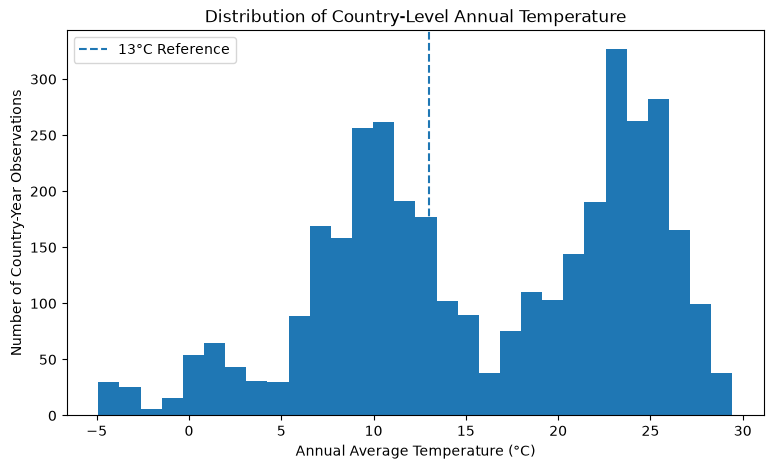

In [33]:
plt.figure(figsize=(9, 5))

plt.hist(
    model_df["temperature"],
    bins=30
)

plt.axvline(
    x=13,
    linestyle="--",
    label="13°C Reference"
)

plt.xlabel(
    "Annual Average Temperature (°C)"
)

plt.ylabel(
    "Number of Country-Year Observations"
)

plt.title(
    "Distribution of Country-Level Annual Temperature"
)

plt.legend()

plt.show()

**Descriptive Temperature–Growth Relationship**

In [34]:
temperature_bins = [-20,0,5,10,15,20,25,30,40]

model_df["temperature_group"] = pd.cut(
    model_df["temperature"],
    bins=temperature_bins
)

temperature_growth = (
    model_df
    .groupby(
        "temperature_group",
        observed=True
    )["future_gdp_pc_growth"]
    .mean()
)

temperature_growth

temperature_group
(-20, 0]    1.532461
(0, 5]      2.723104
(5, 10]     2.595628
(10, 15]    2.496544
(15, 20]    1.928789
(20, 25]    2.680309
(25, 30]    2.843712
Name: future_gdp_pc_growth, dtype: float64

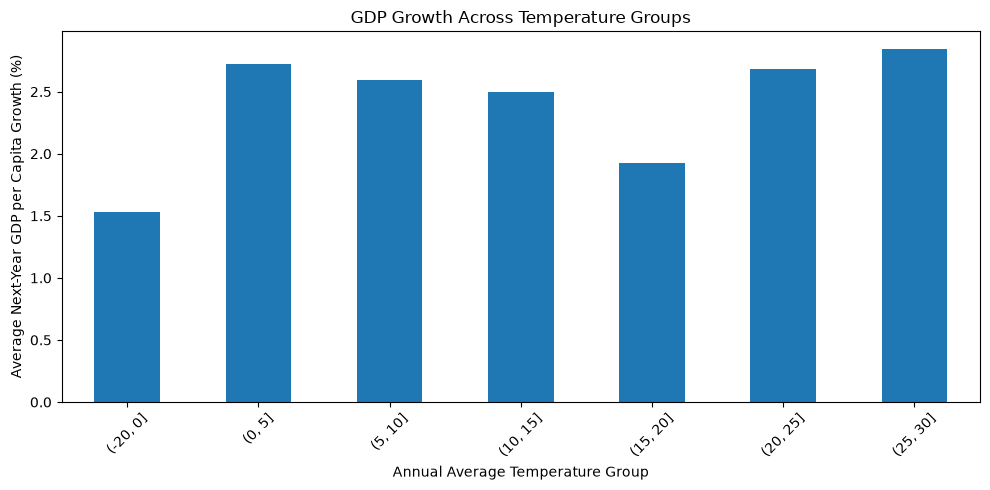

In [35]:
plt.figure(figsize=(10, 5))

temperature_growth.plot(
    kind="bar"
)

plt.xlabel(
    "Annual Average Temperature Group"
)

plt.ylabel(
    "Average Next-Year GDP per Capita Growth (%)"
)

plt.title(
    "GDP Growth Across Temperature Groups"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()

In [36]:
correlations = (
    model_df[
        features
        + ["future_gdp_pc_growth"]
    ]
    .corr()[
        "future_gdp_pc_growth"
    ]
    .sort_values(
        ascending=False
    )
)

correlations.round(3)

future_gdp_pc_growth     1.000
current_gdp_pc_growth    0.426
co2_growth               0.137
co2_per_gdp              0.074
co2_per_capita           0.065
energy_per_gdp           0.037
heat_stress              0.029
oil_co2_per_capita       0.028
temperature_change       0.028
temperature_squared      0.028
temperature              0.022
energy_per_capita        0.015
population_growth        0.009
log_gdp_pc              -0.005
coal_co2_per_capita     -0.013
Name: future_gdp_pc_growth, dtype: float64

In [37]:
all_years = np.array(
    sorted(
        model_df["year"].unique()
    )
)

train_years, test_years = train_test_split(
    all_years,
    test_size=0.20,
    shuffle=False
)

In [38]:
train_years = train_years[:-1]

In [39]:
print(
    "Training years:",
    train_years[0],
    "to",
    train_years[-1]
)

print(
    "Test years:",
    test_years[0],
    "to",
    test_years[-1]
)

Training years: 1991 to 2013
Test years: 2015 to 2021


In [40]:
train_df = model_df[
    model_df["year"].isin(
        train_years
    )
].copy()

test_df = model_df[
    model_df["year"].isin(
        test_years
    )
].copy()

train_df = train_df.sort_values(
    by=[
        "year",
        "country"
    ]
).reset_index(drop=True)

test_df = test_df.sort_values(
    by=[
        "year",
        "country"
    ]
).reset_index(drop=True)

In [41]:
X_train = train_df[features]

y_train = train_df[
    "future_gdp_pc_growth"
]

X_test = test_df[features]

y_test = test_df[
    "future_gdp_pc_growth"
]

In [42]:
print(
    "Training observations:",
    len(X_train)
)

print(
    "Test observations:",
    len(X_test)
)

Training observations: 2672
Test observations: 836


**Historical-Mean Benchmark**

In [43]:
historical_mean = y_train.mean()

historical_mean_pred = np.repeat(
    historical_mean,
    len(y_test)
)

print(
    "Historical mean GDP growth:",
    historical_mean
)

Historical mean GDP growth: 2.980322880154303


In [44]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

In [45]:
ols = LinearRegression()

ols.fit(
    X_train_scaled,
    y_train
)

ols_pred = ols.predict(
    X_test_scaled
)

In [46]:
ols_coefficients = pd.Series(
    ols.coef_,
    index=features,
    name="OLS"
)

ols_coefficients.round(4)

temperature             -0.6226
temperature_squared      0.0105
temperature_change       0.2361
heat_stress              0.7783
current_gdp_pc_growth    2.5805
log_gdp_pc              -0.1634
population_growth       -0.7007
co2_growth               0.3729
co2_per_capita           1.3813
co2_per_gdp              0.6477
energy_per_capita       -0.4124
energy_per_gdp          -0.4798
coal_co2_per_capita     -0.5866
oil_co2_per_capita      -0.4986
Name: OLS, dtype: float64

We will perform TimeSeriesSplit on the unique years, and then translate those years into country-year rows.

**Create Panel-Aware Cross-Validation Folds**

In [47]:
training_years = np.array(
    sorted(
        train_df["year"].unique()
    )
)

year_splitter = TimeSeriesSplit(
    n_splits=5,
    gap=1
)

cv_splits = []

for year_train_index, year_valid_index in year_splitter.split(
    training_years
):

    cv_train_years = training_years[
        year_train_index
    ]

    cv_valid_years = training_years[
        year_valid_index
    ]

    train_rows = np.where(
        train_df["year"].isin(
            cv_train_years
        )
    )[0]

    valid_rows = np.where(
        train_df["year"].isin(
            cv_valid_years
        )
    )[0]

    cv_splits.append(
        (
            train_rows,
            valid_rows
        )
    )

In [48]:
print(
    "Number of CV folds:",
    len(cv_splits)
)

Number of CV folds: 5


In [ ]:
alpha_values = np.logspace(-4,1,150)

**Full LASSO Pipeline**

In [50]:
full_lasso_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "lasso",
        Lasso(
            max_iter=100000
        )
    )
])

**Tune the Full LASSO**

In [51]:
parameter_grid = {
    "lasso__alpha":
    alpha_values
}

full_lasso_search = GridSearchCV(
    estimator=full_lasso_pipeline,
    param_grid=parameter_grid,
    cv=cv_splits,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

full_lasso_search.fit(
    X_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ter=100000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'lasso__alpha': array([1.0000...00000000e+01])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...83, 784, 785]), ...), (array([ 0, ...shape=(1129,)), ...), ...]"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for ca

In [52]:
best_alpha = (
    full_lasso_search
    .best_params_[
        "lasso__alpha"
    ]
)

print(
    "Best full-model alpha:",
    best_alpha
)

Best full-model alpha: 0.007008701824056907


In [53]:
best_full_lasso = (
    full_lasso_search
    .best_estimator_
)

full_lasso_pred = (
    best_full_lasso.predict(
        X_test
    )
)

In [54]:
lasso_coefficients = pd.Series(
    best_full_lasso
    .named_steps["lasso"]
    .coef_,
    index=features,
    name="LASSO"
)

lasso_coefficients.round(4)

temperature             -0.4444
temperature_squared      0.0000
temperature_change       0.2265
heat_stress              0.6364
current_gdp_pc_growth    2.5839
log_gdp_pc              -0.1818
population_growth       -0.6794
co2_growth               0.3676
co2_per_capita           1.2206
co2_per_gdp              0.5879
energy_per_capita       -0.3002
energy_per_gdp          -0.4012
coal_co2_per_capita     -0.5349
oil_co2_per_capita      -0.4489
Name: LASSO, dtype: float64

In [55]:
selected_features = (
    lasso_coefficients[
        lasso_coefficients != 0
    ]
)

selected_features

temperature             -0.444375
temperature_change       0.226472
heat_stress              0.636357
current_gdp_pc_growth    2.583944
log_gdp_pc              -0.181825
population_growth       -0.679444
co2_growth               0.367561
co2_per_capita           1.220576
co2_per_gdp              0.587931
energy_per_capita       -0.300229
energy_per_gdp          -0.401206
coal_co2_per_capita     -0.534864
oil_co2_per_capita      -0.448915
Name: LASSO, dtype: float64

In [56]:
eliminated_features = (
    lasso_coefficients[
        lasso_coefficients == 0
    ]
)

eliminated_features

temperature_squared    0.0
Name: LASSO, dtype: float64

In [57]:
print(
    "Total candidate predictors:",
    len(features)
)

print(
    "Predictors selected:",
    len(selected_features)
)

print(
    "Predictors eliminated:",
    len(eliminated_features)
)

Total candidate predictors: 14
Predictors selected: 13
Predictors eliminated: 1


In [58]:
selected_climate_features = [
    feature
    for feature in climate_features
    if lasso_coefficients[
        feature
    ] != 0
]

print(
    "Climate predictors selected:"
)

print(
    selected_climate_features
)

print(
    "Number of direct climate predictors selected:",
    len(selected_climate_features)
)

Climate predictors selected:
['temperature', 'temperature_change', 'heat_stress']
Number of direct climate predictors selected: 3


**OLS vs LASSO Coefficient Table**

In [59]:
coefficient_table = pd.DataFrame({
    "OLS":
        ols_coefficients,

    "LASSO":
        lasso_coefficients
})

coefficient_table[
    "Selected_by_LASSO"
] = (
    coefficient_table[
        "LASSO"
    ] != 0
)

coefficient_table[
    "Variable_Group"
] = [
    "Climate"
    if feature in climate_features
    else "Economic/Energy"
    for feature in coefficient_table.index
]

coefficient_table.round(4)

,OLS,LASSO,Selected_by_LASSO,Variable_Group
temperature,-0.6226,-0.4444,True,Climate
temperature_squared,0.0105,0.0000,False,Climate
temperature_change,0.2361,0.2265,True,Climate
heat_stress,0.7783,0.6364,True,Climate
current_gdp_pc_growth,2.5805,2.5839,True,Economic/Energy
log_gdp_pc,-0.1634,-0.1818,True,Economic/Energy
population_growth,-0.7007,-0.6794,True,Economic/Energy
co2_growth,0.3729,0.3676,True,Economic/Energy
co2_per_capita,1.3813,1.2206,True,Economic/Energy
co2_per_gdp,0.6477,0.5879,True,Economic/Energy


**Build the Economic/Energy-Only LASSO**

In [60]:
X_train_economic = train_df[
    economic_features
]

X_test_economic = test_df[
    economic_features
]

In [61]:
economic_lasso_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "lasso",
        Lasso(
            max_iter=100000
        )
    )
])

economic_lasso_search = GridSearchCV(
    estimator=economic_lasso_pipeline,
    param_grid=parameter_grid,
    cv=cv_splits,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

economic_lasso_search.fit(
    X_train_economic,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ter=100000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'lasso__alpha': array([1.0000...00000000e+01])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...83, 784, 785]), ...), (array([ 0, ...shape=(1129,)), ...), ...]"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for ca

In [62]:
economic_best_alpha = (
    economic_lasso_search
    .best_params_[
        "lasso__alpha"
    ]
)

print(
    "Best economic-only alpha:",
    economic_best_alpha
)

Best economic-only alpha: 0.0111424287523251


In [63]:
best_economic_lasso = (
    economic_lasso_search
    .best_estimator_
)

economic_lasso_pred = (
    best_economic_lasso.predict(
        X_test_economic
    )
)

In [64]:
def evaluate_model(
    y_true,
    y_pred
):

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    return rmse, mae, r2

In [65]:
mean_rmse, mean_mae, mean_r2 = evaluate_model(
    y_test,
    historical_mean_pred
)

ols_rmse, ols_mae, ols_r2 = evaluate_model(
    y_test,
    ols_pred
)

economic_rmse, economic_mae, economic_r2 = evaluate_model(
    y_test,
    economic_lasso_pred
)

full_rmse, full_mae, full_r2 = evaluate_model(
    y_test,
    full_lasso_pred
)

**Performance Table**

In [66]:
performance = pd.DataFrame({
    "Model": [
        "Historical Mean",
        "OLS",
        "Economic/Energy LASSO",
        "Climate-Economy LASSO"
    ],

    "RMSE": [
        mean_rmse,
        ols_rmse,
        economic_rmse,
        full_rmse
    ],

    "MAE": [
        mean_mae,
        ols_mae,
        economic_mae,
        full_mae
    ],

    "R2": [
        mean_r2,
        ols_r2,
        economic_r2,
        full_r2
    ]
})

performance.round(4)

,Model,RMSE,MAE,R2
0,Historical Mean,5.1495,3.3404,-0.1175
1,OLS,5.2081,3.3452,-0.1431
2,Economic/Energy LASSO,5.1715,3.3171,-0.1271
3,Climate-Economy LASSO,5.2004,3.3384,-0.1398


In [67]:
def out_of_sample_r2(
    y_true,
    model_pred,
    benchmark_pred
):

    model_error = np.sum(
        (
            y_true.values
            - model_pred
        ) ** 2
    )

    benchmark_error = np.sum(
        (
            y_true.values
            - benchmark_pred
        ) ** 2
    )

    return (
        1
        - model_error
        / benchmark_error
    )

In [68]:
ols_oos_r2 = out_of_sample_r2(
    y_test,
    ols_pred,
    historical_mean_pred
)

economic_oos_r2 = out_of_sample_r2(
    y_test,
    economic_lasso_pred,
    historical_mean_pred
)

full_oos_r2 = out_of_sample_r2(
    y_test,
    full_lasso_pred,
    historical_mean_pred
)

print(
    "OLS OOS R2:",
    round(
        ols_oos_r2,
        4
    )
)

print(
    "Economic/Energy LASSO OOS R2:",
    round(
        economic_oos_r2,
        4
    )
)

print(
    "Climate-Economy LASSO OOS R2:",
    round(
        full_oos_r2,
        4
    )
)

OLS OOS R2: -0.0229
Economic/Energy LASSO OOS R2: -0.0086
Climate-Economy LASSO OOS R2: -0.0199


**Did Climate Information Improve RMSE?**

In [69]:
climate_rmse_gain = (
    economic_rmse
    - full_rmse
)

print(
    "RMSE improvement from adding climate variables:",
    round(
        climate_rmse_gain,
        4
    )
)

RMSE improvement from adding climate variables: -0.0289


Economic RMSE − Full RMSE > 0 means adding climate variables improved forecasting.

In [70]:
climate_rmse_gain_percent = (
    (
        economic_rmse
        - full_rmse
    )
    / economic_rmse
    * 100
)

print(
    "Percentage RMSE improvement from climate variables:",
    round(
        climate_rmse_gain_percent,
        2
    ),
    "%"
)

Percentage RMSE improvement from climate variables: -0.56 %


**Plot: Final LASSO Coefficients**

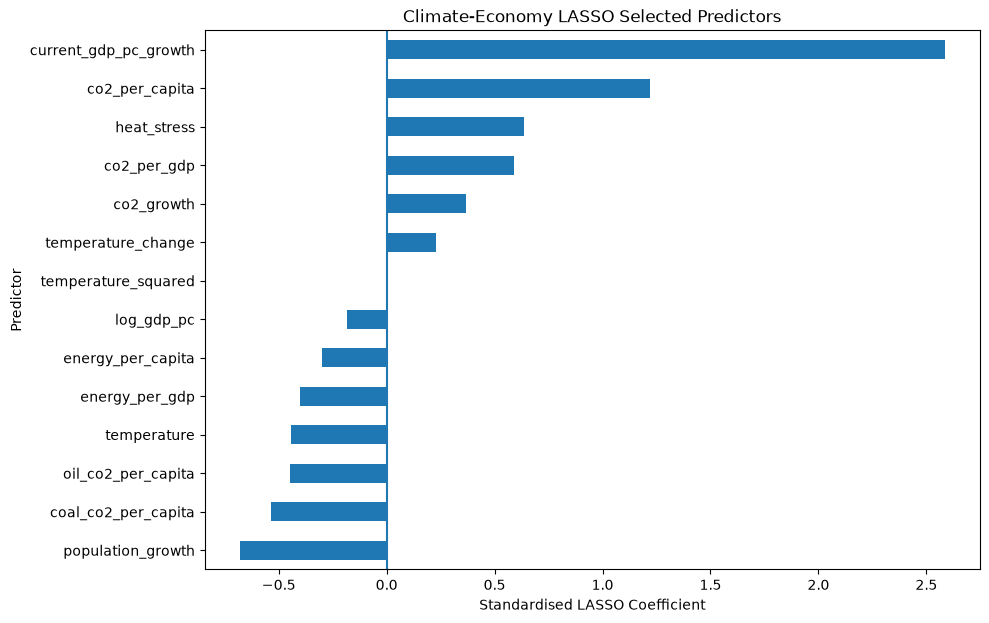

In [71]:
lasso_coefficients.sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.axvline(
    x=0
)

plt.xlabel(
    "Standardised LASSO Coefficient"
)

plt.ylabel(
    "Predictor"
)

plt.title(
    "Climate-Economy LASSO Selected Predictors"
)

plt.show()

In [72]:
path_scaler = StandardScaler()

X_train_path = (
    path_scaler.fit_transform(
        X_train
    )
)

path_alphas = np.logspace(
    -4,
    1,
    150
)

coefficient_path = []

for alpha in path_alphas:

    model = Lasso(
        alpha=alpha,
        max_iter=100000
    )

    model.fit(
        X_train_path,
        y_train
    )

    coefficient_path.append(
        model.coef_
    )

coefficient_path = np.array(
    coefficient_path
)

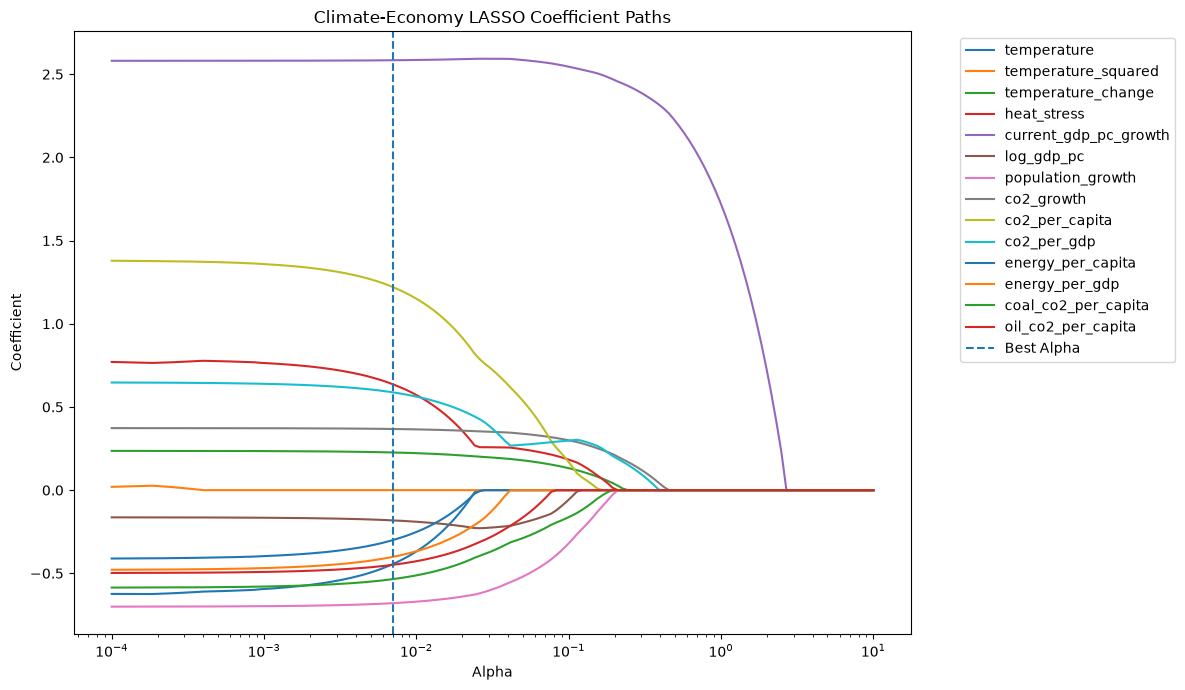

In [73]:
plt.figure(figsize=(12, 7))

for i, feature in enumerate(features):

    plt.semilogx(
        path_alphas,
        coefficient_path[:, i],
        label=feature
    )

plt.axvline(
    best_alpha,
    linestyle="--",
    label="Best Alpha"
)

plt.xlabel(
    "Alpha"
)

plt.ylabel(
    "Coefficient"
)

plt.title(
    "Climate-Economy LASSO Coefficient Paths"
)

plt.legend(
    bbox_to_anchor=(
        1.05,
        1
    ),
    loc="upper left"
)

plt.tight_layout()

plt.show()

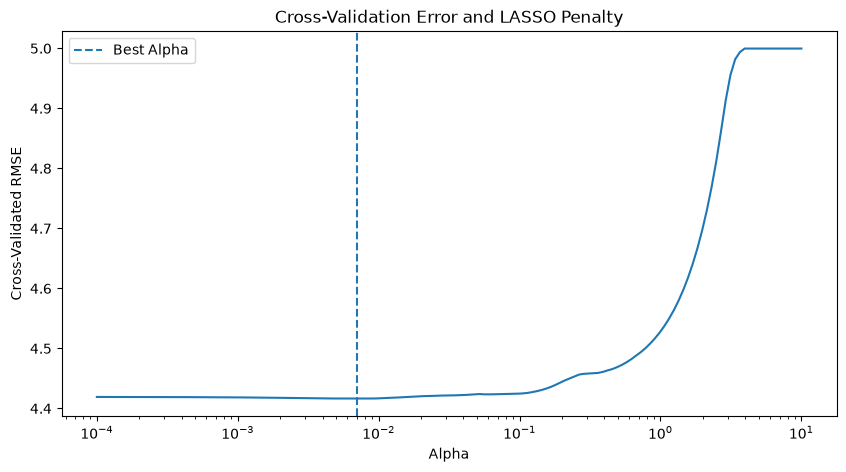

In [74]:
cv_results = pd.DataFrame(
    full_lasso_search.cv_results_
)

cv_results["RMSE"] = (
    -cv_results[
        "mean_test_score"
    ]
)

cv_results["alpha"] = (
    cv_results[
        "param_lasso__alpha"
    ].astype(float)
)

plt.figure(figsize=(10, 5))

plt.semilogx(
    cv_results["alpha"],
    cv_results["RMSE"]
)

plt.axvline(
    best_alpha,
    linestyle="--",
    label="Best Alpha"
)

plt.xlabel(
    "Alpha"
)

plt.ylabel(
    "Cross-Validated RMSE"
)

plt.title(
    "Cross-Validation Error and LASSO Penalty"
)

plt.legend()

plt.show()

**Create Test Results**

In [75]:
test_results = test_df[[
    "country",
    "year",
    "temperature"
]].copy()

test_results[
    "Actual"
] = y_test.values

test_results[
    "Historical_Mean"
] = historical_mean_pred

test_results[
    "OLS"
] = ols_pred

test_results[
    "Economic_LASSO"
] = economic_lasso_pred

test_results[
    "Climate_Economy_LASSO"
] = full_lasso_pred

In [76]:
test_results.head(10).round(3)

,country,year,temperature,Actual,Historical_Mean,OLS,Economic_LASSO,Climate_Economy_LASSO
0,Afghanistan,2015,12.977,-0.037,2.98,-0.747,-0.305,-0.701
1,Albania,2015,13.216,3.342,2.98,1.974,2.318,2.004
2,Algeria,2015,23.893,1.100,2.98,2.694,2.520,2.642
3,Argentina,2015,15.123,-3.024,2.98,2.271,2.505,2.292
4,Armenia,2015,7.269,0.277,2.98,3.385,3.376,3.299
5,Australia,2015,22.506,1.079,2.98,1.522,1.337,1.581
6,Austria,2015,7.931,0.894,2.98,1.276,1.411,1.263
7,Azerbaijan,2015,12.743,-4.199,2.98,1.347,1.800,1.363
8,Bangladesh,2015,25.454,5.902,2.98,5.082,4.727,5.037
9,Belarus,2015,8.641,-2.657,2.98,0.996,0.700,0.900


**Average Forecasts Across Countries by Year**

In [77]:
yearly_results = (
    test_results
    .groupby("year")[[
        "Actual",
        "Historical_Mean",
        "OLS",
        "Economic_LASSO",
        "Climate_Economy_LASSO"
    ]]
    .mean()
)

yearly_results.round(3)

,Actual,Historical_Mean,OLS,Economic_LASSO,Climate_Economy_LASSO
year,,,,,
2015,1.691,2.98,2.495,2.394,2.488
2016,2.198,2.98,2.492,2.462,2.486
2017,2.200,2.98,2.694,2.702,2.687
2018,1.457,2.98,2.767,2.676,2.758
2019,-5.328,2.98,2.503,2.393,2.492
2020,4.545,2.98,-0.285,-0.325,-0.296
2021,2.391,2.98,3.747,3.768,3.732


**Plot: Actual vs Forecast Growth**

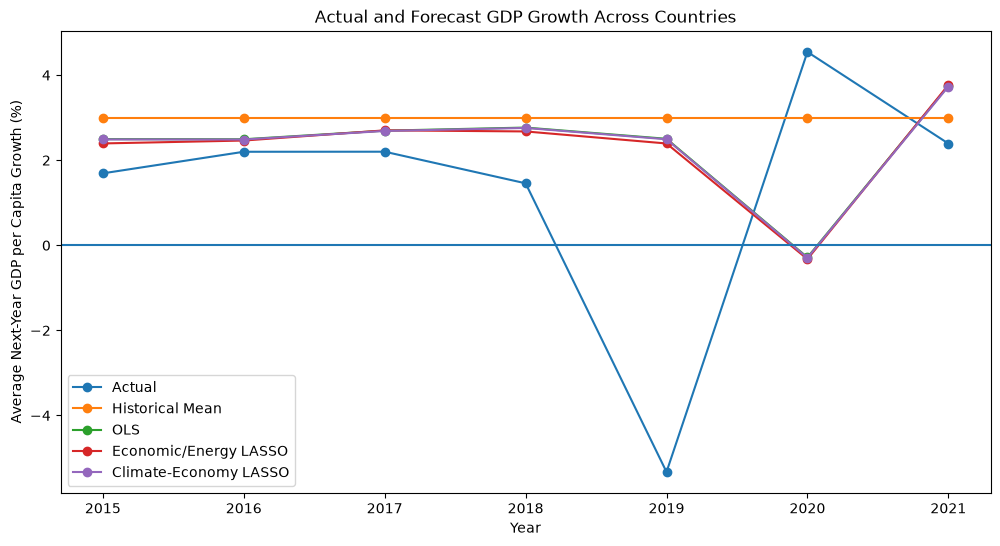

In [78]:
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_results.index,
    yearly_results["Actual"],
    marker="o",
    label="Actual"
)

plt.plot(
    yearly_results.index,
    yearly_results[
        "Historical_Mean"
    ],
    marker="o",
    label="Historical Mean"
)

plt.plot(
    yearly_results.index,
    yearly_results["OLS"],
    marker="o",
    label="OLS"
)

plt.plot(
    yearly_results.index,
    yearly_results[
        "Economic_LASSO"
    ],
    marker="o",
    label="Economic/Energy LASSO"
)

plt.plot(
    yearly_results.index,
    yearly_results[
        "Climate_Economy_LASSO"
    ],
    marker="o",
    label="Climate-Economy LASSO"
)

plt.axhline(
    y=0
)

plt.xlabel(
    "Year"
)

plt.ylabel(
    "Average Next-Year GDP per Capita Growth (%)"
)

plt.title(
    "Actual and Forecast GDP Growth Across Countries"
)

plt.legend()

plt.show()

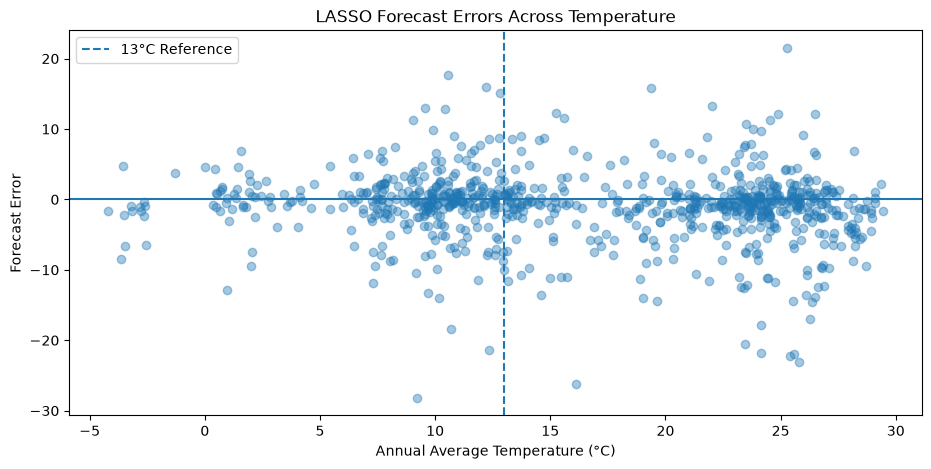

In [79]:
full_lasso_residuals = (
    y_test.values
    - full_lasso_pred
)

plt.figure(figsize=(11, 5))

plt.scatter(
    test_results["temperature"],
    full_lasso_residuals,
    alpha=0.4
)

plt.axhline(
    y=0
)

plt.axvline(
    x=13,
    linestyle="--",
    label="13°C Reference"
)

plt.xlabel(
    "Annual Average Temperature (°C)"
)

plt.ylabel(
    "Forecast Error"
)

plt.title(
    "LASSO Forecast Errors Across Temperature"
)

plt.legend()

plt.show()

**Compare Performance Above and Below 13°C**

In [80]:
cool_mask = (
    test_results[
        "temperature"
    ] <= 13
)

hot_mask = (
    test_results[
        "temperature"
    ] > 13
)

In [81]:
cool_rmse = np.sqrt(
    mean_squared_error(
        test_results.loc[
            cool_mask,
            "Actual"
        ],
        test_results.loc[
            cool_mask,
            "Climate_Economy_LASSO"
        ]
    )
)

hot_rmse = np.sqrt(
    mean_squared_error(
        test_results.loc[
            hot_mask,
            "Actual"
        ],
        test_results.loc[
            hot_mask,
            "Climate_Economy_LASSO"
        ]
    )
)

print(
    "RMSE for observations at or below 13°C:",
    round(
        cool_rmse,
        4
    )
)

print(
    "RMSE for observations above 13°C:",
    round(
        hot_rmse,
        4
    )
)

RMSE for observations at or below 13°C: 4.7555
RMSE for observations above 13°C: 5.4806


It tells us whether forecasting performance differs across temperature regimes.

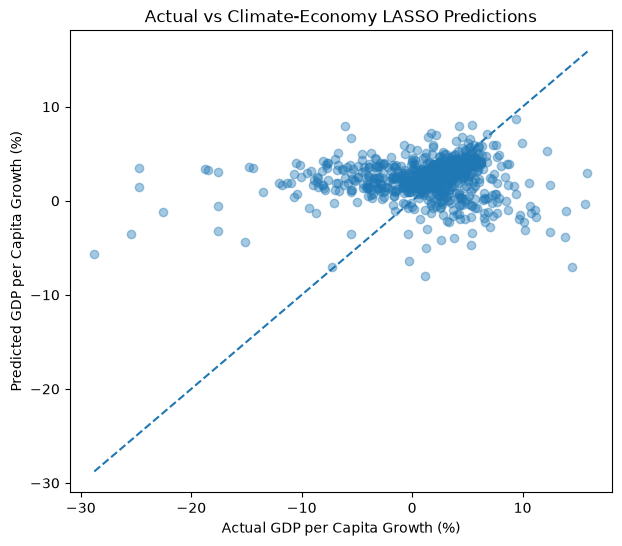

In [82]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    full_lasso_pred,
    alpha=0.4
)

minimum = min(
    y_test.min(),
    full_lasso_pred.min()
)

maximum = max(
    y_test.max(),
    full_lasso_pred.max()
)

plt.plot(
    [
        minimum,
        maximum
    ],
    [
        minimum,
        maximum
    ],
    linestyle="--"
)

plt.xlabel(
    "Actual GDP per Capita Growth (%)"
)

plt.ylabel(
    "Predicted GDP per Capita Growth (%)"
)

plt.title(
    "Actual vs Climate-Economy LASSO Predictions"
)

plt.show()

In [83]:
performance.to_csv(
    "problem_13_model_performance.csv",
    index=False
)

coefficient_table.to_csv(
    "problem_13_coefficients.csv"
)

test_results.to_csv(
    "problem_13_country_year_forecasts.csv",
    index=False
)

yearly_results.to_csv(
    "problem_13_yearly_forecasts.csv"
)

cv_results.to_csv(
    "problem_13_lasso_cv_results.csv",
    index=False
)

## END